In [1]:
import subprocess
from pathlib import Path

zip_file_path = Path("/content/nightflash-edge-colab.zip")

if zip_file_path.exists():
    subprocess.run(["unzip", "-q", str(zip_file_path), "-d", "/content"], check=True)
    print(f"Successfully unzipped {zip_file_path.name} to /content/")
else:
    print(f"Error: {zip_file_path.name} not found in /content/. Please ensure the file is uploaded.")

Successfully unzipped nightflash-edge-colab.zip to /content/


# Night Flash Edge — Google Colab

Unpaired image-to-image training for the disposable-camera / Night Flash look.

This notebook is generated from the repository and is kept in sync with:

- `docs/COLAB.md` — full written workflow, Colab CLI, and Colab MCP options
- `docs/TRAINING.md` — phase-by-phase local training
- `docs/COREML.md` — Core ML export and iOS integration

**Runtime:** GPU → T4 (cheapest) or L4/A100 for 512px.

The TUI (`nightflash-tui`) does **not** work in Colab — it needs a local terminal. Everything else is CLI-driven, which is what this notebook uses.

## 1. Get the code

Run **one** of the three options below.

**Option A — GitHub (recommended, repeatable)**

Push the repo from your Mac first, then set `REPO_URL` below.

**Option B — Zip upload**

On your Mac:

```bash
python scripts/make_colab_bundle.sh      # or: ./scripts/make_colab_bundle.sh
```

Then use the Colab file browser to upload `dist/nightflash-edge-colab.zip` to `/content/`, and run Option C.

**Option C — Google Drive**

Put the zip in Drive and set `ZIP_ON_DRIVE` below.

The zip deliberately excludes `training_photos/`, `runs/`, and checkpoints — your dataset is handled separately below.

In [2]:
import os
import subprocess
from pathlib import Path

# ---- EDIT THESE TWO LINES ONLY ----
REPO_URL = ""          # e.g. "https://github.com/you/nightflash-edge"
REPO_BRANCH = "main"
ZIP_ON_DRIVE = ""      # e.g. "nightflash-edge/nightflash-edge-colab.zip"
# ---------------------------------

PROJECT = Path("/content/nightflash-edge")

if REPO_URL:
    if not PROJECT.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(PROJECT)],
            check=True,
        )
    print(f"cloned into {PROJECT}")
elif ZIP_ON_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    zip_path = Path("/content/drive/MyDrive") / ZIP_ON_DRIVE
    if not zip_path.exists():
        raise FileNotFoundError(f"{zip_path} not found on Drive")
    subprocess.run(["unzip", "-q", str(zip_path), "-d", "/content"], check=True)
    print(f"unzipped into {PROJECT}")
else:
    candidates = sorted(Path("/content").glob("*.zip"))
    if not candidates:
        raise RuntimeError(
            "No code found. Either set REPO_URL, set ZIP_ON_DRIVE, or upload "
            "nightflash-edge-colab.zip to /content/ via the Colab file browser."
        )
    print(f"using uploaded zip: {candidates[0]}")
    subprocess.run(["unzip", "-q", str(candidates[0]), "-d", "/content"], check=True)

assert (PROJECT / "pyproject.toml").exists(), f"expected the repo at {PROJECT}"
print("ok:", PROJECT)

using uploaded zip: /content/nightflash-edge-colab.zip


CalledProcessError: Command '['unzip', '-q', '/content/nightflash-edge-colab.zip', '-d', '/content']' returned non-zero exit status 1.

In [3]:
import sys

%cd /content/nightflash-edge
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest", "tqdm"], check=True)
print("installed")

[Errno 2] No such file or directory: '/content/nightflash-edge'
/content
installed


In [4]:
%pwd

'/content'

In [5]:
%ls

colab/                     pyproject.toml           requirements.txt  tests/
docs/                      README.md                sample_data/
LICENSE                    requirements-coreml.txt  scripts/
nightflash-edge-colab.zip  requirements-tui.txt     src/


## 2. Verify the runtime

In [15]:
import torch

print("torch      :", torch.__version__)
print("cuda avail :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu        :", torch.cuda.get_device_name(0))
    print("vram GB    :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
else:
    print("WARNING: no GPU. Training will be very slow. Runtime -> Change runtime type -> GPU.")

torch      : 2.11.0+cu128
cuda avail : True
gpu        : Tesla T4
vram GB    : 15.6


In [16]:
subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_shapes.py"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'tests/test_shapes.py'], returncode=0)

## 3. Mount Google Drive and set paths

**Put the dataset in Drive before continuing.** `/content` is wiped when the runtime ends; Drive is not.

Expected layout on Drive:

```
MyDrive/nightflash-edge/
  training_photos/
    normal_photos/      # source domain
    disposable_photos/  # target domain
    validation_photos/  # held-out source images
```

In [34]:
from google.colab import drive

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/nightflash-edge")  # EDIT if your folder differs
DATASET = DRIVE_ROOT / "training_photos"
RUNS = DRIVE_ROOT / "runs"

SOURCE_DIR = DATASET / "normal_photos"
TARGET_DIR = DATASET / "disposable_photos"
VAL_DIR = DATASET / "validation_photos"

for label, path in [("source", SOURCE_DIR), ("target", TARGET_DIR), ("val", VAL_DIR)]:
    if not path.is_dir():
        raise FileNotFoundError(
            f"{label} directory missing: {path}\n"
            "Upload training_photos/ to Drive and update DRIVE_ROOT if the path differs."
        )
    count = sum(1 for p in path.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
    print(f"{label:7s} {count:6d} images  {path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
source    1001 images  /content/drive/MyDrive/nightflash-edge/training_photos/normal_photos
target     209 images  /content/drive/MyDrive/nightflash-edge/training_photos/disposable_photos
val         20 images  /content/drive/MyDrive/nightflash-edge/training_photos/validation_photos


### ⚠️ Read this before training

A small **target** set is the limiting factor, not the source set.

| Domain | Yours | Effect |
|---|---:|---|
| source | 1000 | fine |
| target | 210 | **the discriminator will memorise it** |
| held-out source | 20 | fine for content checks |
| held-out target | 0 | you cannot measure target-domain generalisation |

With 45 target images, expect:

- style to appear quickly, then overfit by epoch 2–5
- a discriminator loss near zero (it has memorised the set)
- outputs that look great on your 45 references and worse on anything else

Two things worth doing first:

1. Grow the target set with `scripts/scrape_dataset.py --domain disposable --count 1000`, then re-run the curator's aesthetic screening.
2. Carve a held-out **target** slice (e.g. 15 of the 45) for honest evaluation instead of evaluating on training targets.

You can still use the current 45 images for a **pipeline** pilot. Just do not read the resulting metrics as quality.

## 4. Training configuration

Phase 1 is a convolution-only baseline — fastest to train and easiest to export. Move to the hybrid transformer only after this looks plausible.

In [37]:
IMAGE_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 50
NUM_WORKERS = 2
PREVIEW_EVERY = 25
LOG_EVERY = 25
SEED = 0
USE_TRANSFORMER = True   # Phase 1: False. Phase 2: True
USE_AMP = True

OUTPUT_DIR = RUNS / "conv-pilot"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_cmd = [
    sys.executable, "-m", "nightflash.train",
    "--source-dir", str(SOURCE_DIR),
    "--target-dir", str(TARGET_DIR),
    "--output-dir", str(OUTPUT_DIR),
    "--image-size", str(IMAGE_SIZE),
    "--batch-size", str(BATCH_SIZE),
    "--epochs", str(EPOCHS),
    "--num-workers", str(NUM_WORKERS),
    "--preview-every", str(PREVIEW_EVERY),
    "--log-every", str(LOG_EVERY),
    "--seed", str(SEED),
    "--device", "cuda" if torch.cuda.is_available() else "cpu",
]
if USE_AMP and torch.cuda.is_available():
    train_cmd.append("--amp")
if not USE_TRANSFORMER:
    train_cmd.append("--no-transformer")

print(" ".join(train_cmd))

/usr/bin/python3 -m nightflash.train --source-dir /content/drive/MyDrive/nightflash-edge/training_photos/normal_photos --target-dir /content/drive/MyDrive/nightflash-edge/training_photos/disposable_photos --output-dir /content/drive/MyDrive/nightflash-edge/runs/conv-pilot --image-size 256 --batch-size 16 --epochs 50 --num-workers 2 --preview-every 25 --log-every 25 --seed 0 --device cuda --amp


## 5. Train

Checkpoints and previews are written to Drive continuously, so a disconnect loses at most `PREVIEW_EVERY` steps.

For a short shakedown first, set `EPOCHS = 1` and `PREVIEW_EVERY = 50`.

In [ ]:
import subprocess, sys, shutil
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/nightflash-edge")
CONV_CKPT = ROOT / "runs/conv-pilot/checkpoints/latest.pt"
WARM_DIR  = ROOT / "runs/hybrid-warm"          # NEW folder, conv run untouched

# 1. Transfer conv weights into a fresh hybrid model, reset optimizer
warm_start_cmd = [
    sys.executable, "/content/scripts/warm_start.py",
    "--checkpoint", str(CONV_CKPT),
    "--output-dir",  str(WARM_DIR),
    "--transformer-blocks", "1",
]

print("Starting warm-up process. Output will be streamed below:\n")
process_warm_up = subprocess.Popen(
    warm_start_cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)
for line in process_warm_up.stdout:
    sys.stdout.write(line)
    sys.stdout.flush()
process_warm_up.wait()
if process_warm_up.returncode != 0:
    raise subprocess.CalledProcessError(process_warm_up.returncode, process_warm_up.args)
print("\nWarm-up process finished.\n")

# 2. Train the hybrid model, resuming from the NEW checkpoint
train_hybrid_cmd = [
    sys.executable, "-m", "nightflash.train",
    "--source-dir",  f"{ROOT}/training_photos/normal_photos",
    "--target-dir",  f"{ROOT}/training_photos/disposable_photos",
    "--output-dir",  str(WARM_DIR),
    "--image-size", "256", "--batch-size", "16",
    "--epochs", "50", "--num-workers", "2",
    "--preview-every", "25", "--log-every", "25",
    "--seed", "0", "--device", "cuda", "--amp",
    "--transformer-blocks", "1",            # REQUIRED: no --no-transformer
    "--resume", str(WARM_DIR / "checkpoints" / "latest.pt"),
]

print("Starting hybrid training. Output will be streamed below, focusing on key updates:\n")
process_train_hybrid = subprocess.Popen(
    train_hybrid_cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)
for line in process_train_hybrid.stdout:
    # Heuristic: print lines containing 'loss_' (indicating metric updates)
    # or lines that are not typical tqdm progress bars (which often contain 'it/s' and 'epoch')
    if "loss_" in line or not ("it/s" in line and "epoch" in line):
        sys.stdout.write(line)
        sys.stdout.flush()
process_train_hybrid.wait()
if process_train_hybrid.returncode != 0:
    raise subprocess.CalledProcessError(process_train_hybrid.returncode, process_train_hybrid.args)
print("\nHybrid training process finished.")

Starting warm-up process. Output will be streamed below:

Warm start: conv-only  ->  hybrid
source checkpoint : /content/drive/MyDrive/nightflash-edge/runs/conv-pilot/checkpoints/latest.pt
old config        : transformer_blocks=0
old epoch/step    : 39 / 4800
old has transformer: False

new config        : transformer_blocks=1
tensors transferred: 46
tensors randomly initialised: 12

OK  every missing key belongs to the new transformer block:
      transformer.0.norm1.weight
      transformer.0.norm1.bias
      transformer.0.qkv.weight
      transformer.0.qkv.bias
      transformer.0.attention_projection.weight
      transformer.0.attention_projection.bias
      ... and 6 more

discriminator     : weights carried over from the conv run
optimizer state   : reset (fresh AdamW moments)

wrote /content/drive/MyDrive/nightflash-edge/runs/hybrid-warm/checkpoints/latest.pt  (5.8 MB)
wrote /content/drive/MyDrive/nightflash-edge/runs/hybrid-warm/warm_start_report.json

Next step — train against

In [39]:
import sys
import subprocess
from pathlib import Path

# Automatically add --resume if a checkpoint exists
CHECKPOINT_FILE = OUTPUT_DIR / "checkpoints" / "latest.pt"
if CHECKPOINT_FILE.exists():
    print(f"Resuming training from: {CHECKPOINT_FILE}")
    current_train_cmd = list(train_cmd)
    current_train_cmd.extend(["--resume", str(CHECKPOINT_FILE)])
else:
    print("Starting new training run.")
    current_train_cmd = list(train_cmd)

print("Starting training. Output will be streamed below, focusing on key updates:\n")

# Use subprocess.Popen to stream output in real-time
process = subprocess.Popen(
    current_train_cmd,
    stdout=subprocess.PIPE, # Capture stdout
    stderr=subprocess.STDOUT, # Redirect stderr to stdout to see all messages
    text=True, # Decode stdout/stderr as text
    bufsize=1 # Line-buffered output
)

# Read and print output line by line as it arrives, filtering for key information
for line in process.stdout:
    # Heuristic: print lines containing 'loss_' (indicating metric updates)
    # or lines that are not typical tqdm progress bars (which often contain 'it/s' and 'epoch')
    if "loss_" in line or not ("it/s" in line and "epoch" in line):
        sys.stdout.write(line)
        sys.stdout.flush() # Ensure output is flushed to the notebook

process.wait() # Wait for the process to terminate

if process.returncode != 0:
    raise subprocess.CalledProcessError(process.returncode, process.args)

print("\nTraining process finished.")

Resuming training from: /content/drive/MyDrive/nightflash-edge/runs/conv-pilot/checkpoints/latest.pt
Starting training. Output will be streamed below, focusing on key updates:

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/src/nightflash/train.py", line 404, in <module>
    main()
    ~~~~^^
  File "/content/src/nightflash/train.py", line 399, in main
    checkpoint = train(args)
  File "/content/src/nightflash/train.py", line 192, in train
    model.load_state_dict(checkpoint["model"])
    ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 2639, in load_state_dict
    raise RuntimeError(
    ...<3 lines>...
    )
RuntimeError: Error(s) in loading state_dict for HybridGenerator:
	Missing key(s) in state_dict: "transformer.0.norm1.weight", "transformer.0.norm1.bias", "transformer.0.qkv.weight", "transform

CalledProcessError: Command '['/usr/bin/python3', '-m', 'nightflash.train', '--source-dir', '/content/drive/MyDrive/nightflash-edge/training_photos/normal_photos', '--target-dir', '/content/drive/MyDrive/nightflash-edge/training_photos/disposable_photos', '--output-dir', '/content/drive/MyDrive/nightflash-edge/runs/conv-pilot', '--image-size', '256', '--batch-size', '16', '--epochs', '50', '--num-workers', '2', '--preview-every', '25', '--log-every', '25', '--seed', '0', '--device', 'cuda', '--amp', '--resume', '/content/drive/MyDrive/nightflash-edge/runs/conv-pilot/checkpoints/latest.pt']' returned non-zero exit status 1.

In [38]:
list(train_cmd)

['/usr/bin/python3',
 '-m',
 'nightflash.train',
 '--source-dir',
 '/content/drive/MyDrive/nightflash-edge/training_photos/normal_photos',
 '--target-dir',
 '/content/drive/MyDrive/nightflash-edge/training_photos/disposable_photos',
 '--output-dir',
 '/content/drive/MyDrive/nightflash-edge/runs/conv-pilot',
 '--image-size',
 '256',
 '--batch-size',
 '16',
 '--epochs',
 '50',
 '--num-workers',
 '2',
 '--preview-every',
 '25',
 '--log-every',
 '25',
 '--seed',
 '0',
 '--device',
 'cuda',
 '--amp']

## 6. Inspect previews without leaving the notebook

Each preview is `source | generated | target reference`.

step-0000250.png


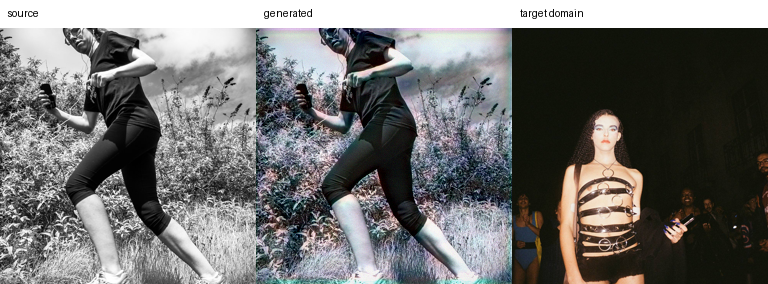

epoch-0002.png


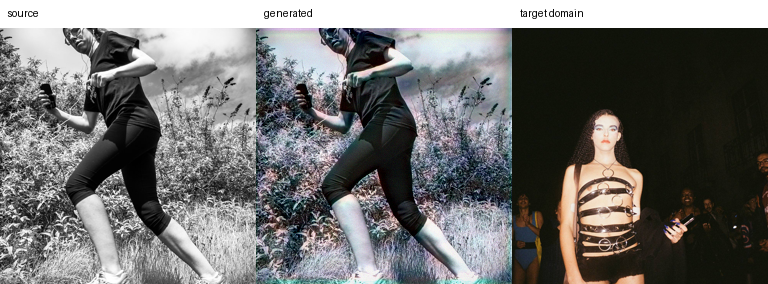

step-0000300.png


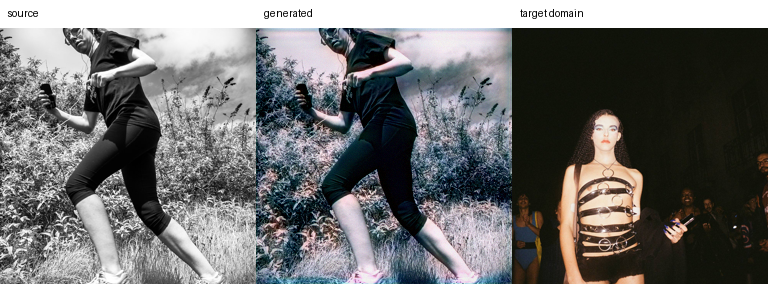

step-0000350.png


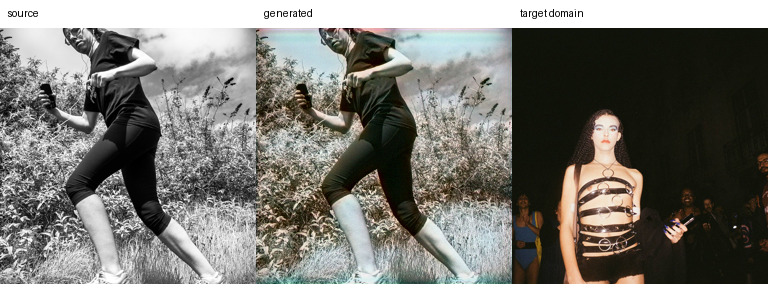

epoch-0003.png


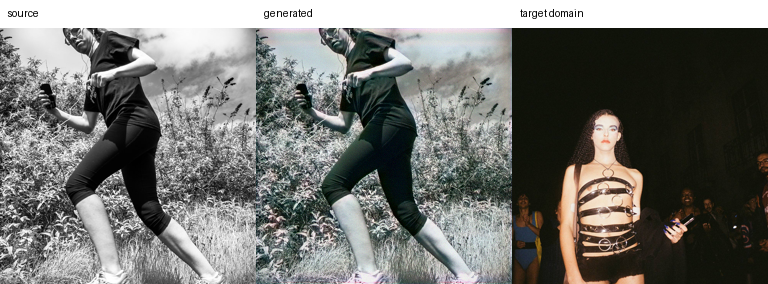

step-0000400.png


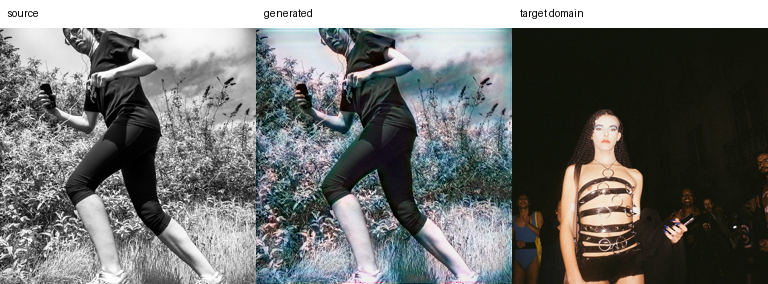

In [25]:
from IPython.display import Image, display

def show_previews(run_dir, n=6):
    previews = sorted((run_dir / "previews").glob("*.png"), key=lambda p: p.stat().st_mtime)
    if not previews:
        print("no previews yet")
        return
    for path in previews[-n:]:
        print(path.name)
        display(Image(filename=str(path), width=768))

show_previews(OUTPUT_DIR)

## 7. Mid-training inference

Test `latest.pt` on a held-out **source** image across several seeds. This is the check that matters for content preservation.

In [ ]:
CHECKPOINT = OUTPUT_DIR / "checkpoints" / "latest.pt"
INFER_DIR = OUTPUT_DIR / "inference"
INFER_DIR.mkdir(parents=True, exist_ok=True)

val_images = sorted(p for p in VAL_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
test_image = val_images[0]
print("testing:", test_image)

for seed in (11, 22, 33):
    dest = INFER_DIR / f"val-seed{seed}.png"
    subprocess.run([
        sys.executable, "-m", "nightflash.infer",
        "--checkpoint", str(CHECKPOINT),
        "--input", str(test_image),
        "--output", str(dest),
        "--seed", str(seed),
        "--device", "cuda" if torch.cuda.is_available() else "cpu",
    ], check=True)
    display(Image(filename=str(dest), width=640))

subprocess.run([
    sys.executable, "-m", "nightflash.infer",
    "--checkpoint", str(CHECKPOINT),
    "--input", str(test_image),
    "--output", str(INFER_DIR / "val-deterministic.png"),
    "--no-effects",
    "--device", "cuda" if torch.cuda.is_available() else "cpu",
], check=True)

## 8. Evaluation

This compares generated vs source content and reports how far the colour statistics are from the training target set. It is **not** a target-domain quality score — with no held-out target images, that cannot be measured yet.

To do it properly, hold out ~15 target images and point `--target-dir` at those.

In [ ]:
subprocess.run([
    sys.executable, "-m", "nightflash.evaluate",
    "--checkpoint", str(CHECKPOINT),
    "--source-dir", str(VAL_DIR),
    "--target-dir", str(TARGET_DIR),
    "--output-json", str(OUTPUT_DIR / "evaluation.json"),
    "--limit", "50",
    "--device", "cuda" if torch.cuda.is_available() else "cpu",
], check=False)

print((OUTPUT_DIR / "evaluation.json").read_text())

## 9. Core ML export

**Export on your Mac, not in Colab.** `coremltools` conversion depends on the host OS and coremltools version, and an `.mlpackage` built on Linux is not something you want to trust for an iOS app.

The supported flow is: train here → download the `.pt` → export on the Mac with `nightflash-export-coreml`.

The cell below only grabs the checkpoint for download. See `docs/COREML.md` for the Mac-side commands.

In [ ]:
print("Download this file to your Mac:")
print("  ", CHECKPOINT)
print()
print("Then on the Mac:")
print("  cd /Users/tejavu/Documents/opencode-experiments/disposable-cam-model-train")
print("  python -m pip install -e '.[coreml]'")
print("  nightflash-export-coreml \\")
print(f"      --checkpoint {CHECKPOINT} \\")
print(f"      --output {OUTPUT_DIR}/NightFlashEdge.mlpackage \\")
print(f"      --image-size {IMAGE_SIZE} --half --deterministic-only")

In [ ]:
from google.colab import files

if CHECKPOINT.exists():
    files.download(str(CHECKPOINT))

## 10. Troubleshooting

| Symptom | Cause / fix |
|---|---|
| `CUDA out of memory` | Lower `BATCH_SIZE`, or `IMAGE_SIZE` to 192 |
| Previews stay grey / unchanged | `residual_scale` too low, or `--effects-strength 0`; try `--adversarial-weight 2.0` |
| Everything gets very dark | Target set is biased dark — curate it; raise `--content-weight` |
| Faces get distorted | Raise `--identity-weight` to `1.5`, lower `--adversarial-weight` |
| Style collapses to one look | Expected with 45 target images — grow the target set |
| `DataLoader` worker crash | Set `NUM_WORKERS = 0` |
| Runtime disconnected | Everything up to the last checkpoint is on Drive; re-run and pass `--resume <latest.pt>` |

## 11. Resume after a disconnect

```python
train_cmd += ["--resume", str(OUTPUT_DIR / "checkpoints" / "latest.pt")]
subprocess.run(train_cmd, check=True)
```

## 12. Phased progression

1. **256px conv baseline** — this notebook, `USE_TRANSFORMER = False`
2. **256px hybrid** — set `USE_TRANSFORMER = True`, new `OUTPUT_DIR`
3. **Mask-aware** — precompute person masks, add `--mask-dir`
4. **512px final** — `IMAGE_SIZE = 512`, `BATCH_SIZE = 2`
5. **Export + benchmark** — on the Mac, per `docs/COREML.md`

Do not change dataset, resolution, and loss weights in the same run — you lose the ability to attribute the change.